# Rescuing Quantum Spin Dynamics with Zero-Noise Extrapolation

**Qompute 2026 - Track 3: Can We Trust a Noisy Quantum Computer?**

This project studies whether error mitigation can recover the magnetization dynamics of a small transverse-field Ising model (TFIM). We compare:

1. Exact classical time evolution
2. Ideal first-order Trotter evolution in Qiskit
3. Trotter evolution under simulated gate noise
4. Zero-noise-extrapolated evolution

**Research question:** How strongly does gate noise distort a four-spin TFIM simulation, and how much accuracy can zero-noise extrapolation recover relative to its additional sampling cost?


## Reproducibility

This notebook is designed to run from top to bottom with Python 3.11-3.14 and current Qiskit 2.x packages. If the imports below fail, install the dependencies in the active notebook kernel and restart it:

```python
%pip install qiskit qiskit-aer numpy scipy matplotlib pylatexenc
```

Real IBM hardware is not required; the challenge permits a well-analyzed simulator project.


In [1]:
from pathlib import Path
import platform
import numpy as np
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer

from scipy.linalg import expm
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

figures_dir = Path.cwd() / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("Figures directory:", figures_dir)


Python: 3.14.7
Qiskit: 2.5.2
Qiskit Aer: 0.17.2
Figures directory: /Users/austinhandongyangicloud.com/Documents/Codex/2026-10-14/ba-s/outputs/figures


## 1. Physical model and known reference

We use an open chain of four spins governed by

$$
H=-J\sum_{i=0}^{N-2} Z_iZ_{i+1}-h\sum_{i=0}^{N-1}X_i.
$$

The $ZZ$ term favors neighboring spins aligning along $z$, while the transverse $X$ field flips spins. These components do not commute, making product-formula approximation necessary. Because four qubits remain classically tractable, exact matrix evolution supplies the known reference required by Track 3.


In [2]:
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    '''Construct an open-chain TFIM Hamiltonian.'''
    terms = []

    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        terms.append(("".join(reversed(pauli)), -J))

    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))

    return SparsePauliOp.from_list(terms)


num_qubits = 4
J = 1.0
h = 1.0
H = tfim_hamiltonian(num_qubits, J, h)

print(f"TFIM on {num_qubits} qubits (J={J}, h={h}):")
print(H)


TFIM on 4 qubits (J=1.0, h=1.0):
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])


## 2. Trotterized quantum evolution

First-order Lie-Trotter synthesis approximates $e^{-iHt}$ by dividing the evolution into short intervals. Smaller intervals reduce algorithmic approximation error but require deeper circuits. We use $\Delta t=0.2$ for 30 steps, producing 31 observations from $t=0$ through $t=6$.


In [3]:
def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order=1):
    '''Prepare |00...0> and apply n_steps of product-formula evolution.'''
    synthesis = LieTrotter(reps=1) if order == 1 else SuzukiTrotter(order=order, reps=1)
    circuit = QuantumCircuit(num_qubits)
    circuit.barrier()
    step = PauliEvolutionGate(H, time=dt, synthesis=synthesis)

    for _ in range(n_steps):
        circuit.append(step, range(num_qubits))

    # Decomposition prevents the statevector primitive from hiding Trotter error
    # by applying an undecomposed evolution gate exactly.
    return circuit.decompose(reps=2)


dt = 0.2
max_steps = 30
times = np.arange(max_steps + 1) * dt

one_step = trotter_evolution_circuit(H, num_qubits, dt, 1)
print("One-step depth:", one_step.depth())
print("One-step two-qubit gates:", one_step.num_nonlocal_gates())


One-step depth: 10
One-step two-qubit gates: 6


## 3. Magnetization observable

We track average magnetization along $z$:

$$
M_z(t)=\frac{1}{N}\sum_{i=0}^{N-1}\langle Z_i\rangle.
$$

The initial state is $|0000\rangle$, so $M_z(0)=1$.


In [4]:
def magnetization_op(num_qubits):
    terms = []
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        terms.append(("".join(reversed(pauli)), 1.0 / num_qubits))
    return SparsePauliOp.from_list(terms)


Mz = magnetization_op(num_qubits)
estimator = StatevectorEstimator()


## 4. Ideal baseline and exact classical evolution

The ideal Trotter result measures algorithmic approximation alone. Exact matrix exponentiation provides the reference. Their difference is Trotter error, not hardware noise.


In [5]:
mz_trotter = []
for n in range(max_steps + 1):
    circuit = trotter_evolution_circuit(H, num_qubits, dt, n)
    result = estimator.run([(circuit, Mz)]).result()
    mz_trotter.append(float(result[0].data.evs))
mz_trotter = np.asarray(mz_trotter)

H_matrix = H.to_matrix()
Mz_matrix = Mz.to_matrix()
psi0 = Statevector.from_label("0" * num_qubits).data

mz_exact = []
for time in times:
    psi_t = expm(-1j * H_matrix * time) @ psi0
    value = np.real(np.conj(psi_t) @ Mz_matrix @ psi_t)
    mz_exact.append(value)
mz_exact = np.asarray(mz_exact)

ideal_error = np.abs(mz_trotter - mz_exact)
print("Maximum Trotter error:", f"{ideal_error.max():.6f}")


Maximum Trotter error: 0.071429


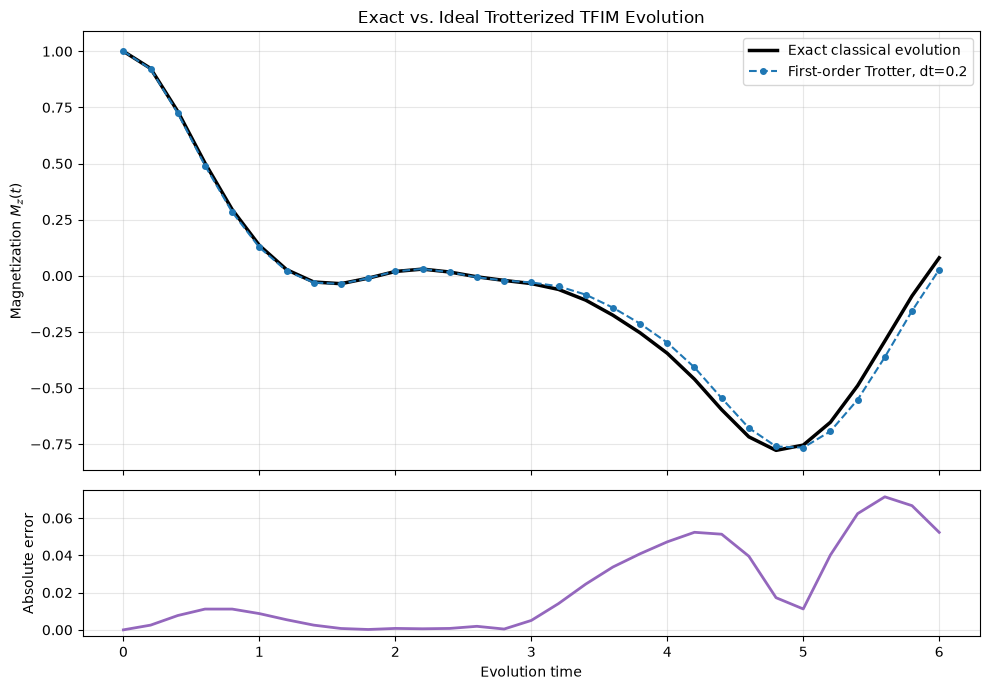

Saved: /Users/austinhandongyangicloud.com/Documents/Codex/2026-10-14/ba-s/outputs/figures/ideal_vs_exact.png


In [6]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)
ax1.plot(times, mz_exact, color="black", linewidth=2.5, label="Exact classical evolution")
ax1.plot(times, mz_trotter, "o--", color="#1f77b4", markersize=4,
         label=f"First-order Trotter, dt={dt}")
ax1.set_ylabel(r"Magnetization $M_z(t)$")
ax1.set_title("Exact vs. Ideal Trotterized TFIM Evolution")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times, ideal_error, color="#9467bd", linewidth=2)
ax2.set_xlabel("Evolution time")
ax2.set_ylabel("Absolute error")
ax2.grid(alpha=0.3)

plt.tight_layout()
ideal_figure_path = figures_dir / "ideal_vs_exact.png"
plt.savefig(ideal_figure_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", ideal_figure_path)


## 5. Simulated hardware noise

We model imperfect gates using depolarizing errors:

- Single-qubit gate error: 0.1%
- Two-qubit CX gate error: 1.0%

The larger two-qubit error reflects the greater difficulty of reliable entangling operations. This controlled model does not capture calibration drift, crosstalk, coherent errors, or qubit-to-qubit variation.


In [7]:
def build_noise_model(noise_scale=1.0):
    noise_model = NoiseModel()
    one_qubit_error = depolarizing_error(0.001 * noise_scale, 1)
    two_qubit_error = depolarizing_error(0.01 * noise_scale, 2)
    noise_model.add_all_qubit_quantum_error(one_qubit_error, ["sx", "x"])
    noise_model.add_all_qubit_quantum_error(two_qubit_error, ["cx"])
    return noise_model


def magnetization_from_counts(counts):
    total_shots = sum(counts.values())
    weighted_sum = 0.0
    for bitstring, count in counts.items():
        bits = bitstring.replace(" ", "")
        value = np.mean([1 if bit == "0" else -1 for bit in bits])
        weighted_sum += count * value
    return weighted_sum / total_shots


# Sanity checks for the count-to-observable conversion.
assert magnetization_from_counts({"0000": 100}) == 1.0
assert magnetization_from_counts({"1111": 100}) == -1.0
assert magnetization_from_counts({"0000": 50, "1111": 50}) == 0.0
print("Count-to-magnetization tests passed.")


Count-to-magnetization tests passed.


In [8]:
def run_noisy_magnetization(circuit, noise_scale=1.0, shots=4096, seed=42):
    measured_circuit = circuit.copy()
    measured_circuit.measure_all()

    simulator = AerSimulator(noise_model=build_noise_model(noise_scale))
    compiled_circuit = transpile(
        measured_circuit,
        basis_gates=["rz", "sx", "x", "cx"],
        optimization_level=1,
        seed_transpiler=seed,
    )
    counts = simulator.run(
        compiled_circuit,
        shots=shots,
        seed_simulator=seed,
    ).result().get_counts()

    return {
        "magnetization": magnetization_from_counts(counts),
        "counts": counts,
        "compiled_circuit": compiled_circuit,
        "depth": compiled_circuit.depth(),
        "cx_count": compiled_circuit.count_ops().get("cx", 0),
    }


initial_test = run_noisy_magnetization(
    trotter_evolution_circuit(H, num_qubits, dt, 0),
    shots=1024,
)
print("Initial noisy magnetization:", initial_test["magnetization"])


Initial noisy magnetization: 1.0


## 6. Noisy baseline

The noisy baseline uses 4,096 shots at each of 31 evolution times. We also record transpiled depth and CX count to connect output degradation with circuit cost.


In [9]:
shots = 4096
mz_noisy = []
compiled_depths = []
compiled_cx_counts = []

for n in range(max_steps + 1):
    result = run_noisy_magnetization(
        trotter_evolution_circuit(H, num_qubits, dt, n),
        noise_scale=1.0,
        shots=shots,
        seed=1000 + n,
    )
    mz_noisy.append(result["magnetization"])
    compiled_depths.append(result["depth"])
    compiled_cx_counts.append(result["cx_count"])

mz_noisy = np.asarray(mz_noisy)
compiled_depths = np.asarray(compiled_depths)
compiled_cx_counts = np.asarray(compiled_cx_counts)

print("Noisy baseline shape:", mz_noisy.shape)
print("Noisy magnetization range:", mz_noisy.min(), "to", mz_noisy.max())


Noisy baseline shape: (31,)
Noisy magnetization range: -0.2069091796875 to 1.0


## 7. Error mitigation with zero-noise extrapolation

We evaluate each circuit at noise scale factors 1, 2, and 3. At every evolution time, a line is fitted through magnetization versus noise scale and extrapolated to scale zero. This is error mitigation, not error correction: it does not identify individual faults, and it requires more executions.


In [10]:
noise_scales = np.asarray([1.0, 2.0, 3.0])
mz_by_scale = {1.0: mz_noisy}

for scale in [2.0, 3.0]:
    values = []
    for n in range(max_steps + 1):
        result = run_noisy_magnetization(
            trotter_evolution_circuit(H, num_qubits, dt, n),
            noise_scale=scale,
            shots=shots,
            seed=1000 + n,
        )
        values.append(result["magnetization"])
    mz_by_scale[scale] = np.asarray(values)

mz_zne = []
for index in range(len(times)):
    observations = np.asarray([mz_by_scale[scale][index] for scale in noise_scales])
    slope, intercept = np.polyfit(noise_scales, observations, deg=1)
    mz_zne.append(intercept)
mz_zne = np.asarray(mz_zne)

print("ZNE shape:", mz_zne.shape)
print("ZNE range:", mz_zne.min(), "to", mz_zne.max())


ZNE shape: (31,)
ZNE range: -0.2822265624999999 to 0.9999999999999994


## 8. Quantitative comparison

RMSE against the ideal Trotter trajectory isolates simulated hardware noise. RMSE against the exact trajectory measures total error, including both Trotter approximation and simulated hardware noise.


In [11]:
def rmse(prediction, reference):
    return float(np.sqrt(np.mean((prediction - reference) ** 2)))


rmse_ideal_vs_exact = rmse(mz_trotter, mz_exact)
rmse_noisy_vs_ideal = rmse(mz_noisy, mz_trotter)
rmse_zne_vs_ideal = rmse(mz_zne, mz_trotter)
rmse_noisy_vs_exact = rmse(mz_noisy, mz_exact)
rmse_zne_vs_exact = rmse(mz_zne, mz_exact)
improvement_percent = 100 * (
    rmse_noisy_vs_ideal - rmse_zne_vs_ideal
) / rmse_noisy_vs_ideal

metrics = {
    "Ideal Trotter vs exact": rmse_ideal_vs_exact,
    "Noisy vs ideal Trotter": rmse_noisy_vs_ideal,
    "ZNE vs ideal Trotter": rmse_zne_vs_ideal,
    "Noisy vs exact": rmse_noisy_vs_exact,
    "ZNE vs exact": rmse_zne_vs_exact,
    "ZNE improvement (%)": improvement_percent,
}

for name, value in metrics.items():
    print(f"{name}: {value:.6f}")


Ideal Trotter vs exact: 0.031859
Noisy vs ideal Trotter: 0.237196
ZNE vs ideal Trotter: 0.204861
Noisy vs exact: 0.239799
ZNE vs exact: 0.206939
ZNE improvement (%): 13.632307


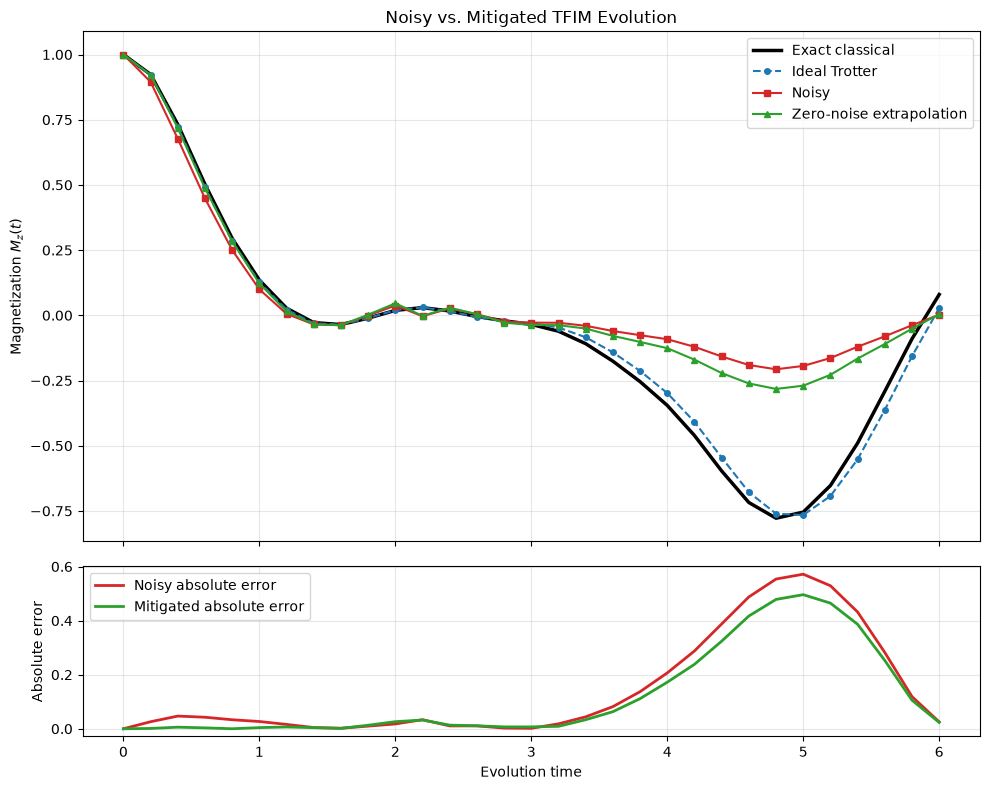

Saved: /Users/austinhandongyangicloud.com/Documents/Codex/2026-10-14/ba-s/outputs/figures/noisy_vs_mitigated.png


In [12]:
noisy_error = np.abs(mz_noisy - mz_trotter)
zne_error = np.abs(mz_zne - mz_trotter)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 8), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)
ax1.plot(times, mz_exact, color="black", linewidth=2.5, label="Exact classical")
ax1.plot(times, mz_trotter, "o--", color="#1f77b4", markersize=4, label="Ideal Trotter")
ax1.plot(times, mz_noisy, "s-", color="#d62728", markersize=4, label="Noisy")
ax1.plot(times, mz_zne, "^-", color="#2ca02c", markersize=4,
         label="Zero-noise extrapolation")
ax1.set_ylabel(r"Magnetization $M_z(t)$")
ax1.set_title("Noisy vs. Mitigated TFIM Evolution")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(times, noisy_error, color="#d62728", linewidth=2, label="Noisy absolute error")
ax2.plot(times, zne_error, color="#2ca02c", linewidth=2, label="Mitigated absolute error")
ax2.set_xlabel("Evolution time")
ax2.set_ylabel("Absolute error")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
comparison_figure_path = figures_dir / "noisy_vs_mitigated.png"
plt.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", comparison_figure_path)


## 9. Cost of mitigation

Accuracy must be evaluated together with added operations, shots, qubits, or runtime. Here, zero-noise extrapolation uses the same logical circuit at three simulated noise strengths, producing a threefold shot overhead.


In [13]:
baseline_shots_per_time = shots
zne_shots_per_time = shots * len(noise_scales)
total_baseline_shots = baseline_shots_per_time * len(times)
total_zne_shots = zne_shots_per_time * len(times)
sampling_overhead = zne_shots_per_time / baseline_shots_per_time

print("Final circuit depth:", compiled_depths[-1])
print("Final CX gate count:", compiled_cx_counts[-1])
print("Baseline shots per time point:", baseline_shots_per_time)
print("ZNE shots per time point:", zne_shots_per_time)
print("Total baseline shots:", total_baseline_shots)
print("Total ZNE shots:", total_zne_shots)
print("Sampling overhead:", f"{sampling_overhead:.1f}x")


Final circuit depth: 334
Final CX gate count: 180
Baseline shots per time point: 4096
ZNE shots per time point: 12288
Total baseline shots: 126976
Total ZNE shots: 380928
Sampling overhead: 3.0x


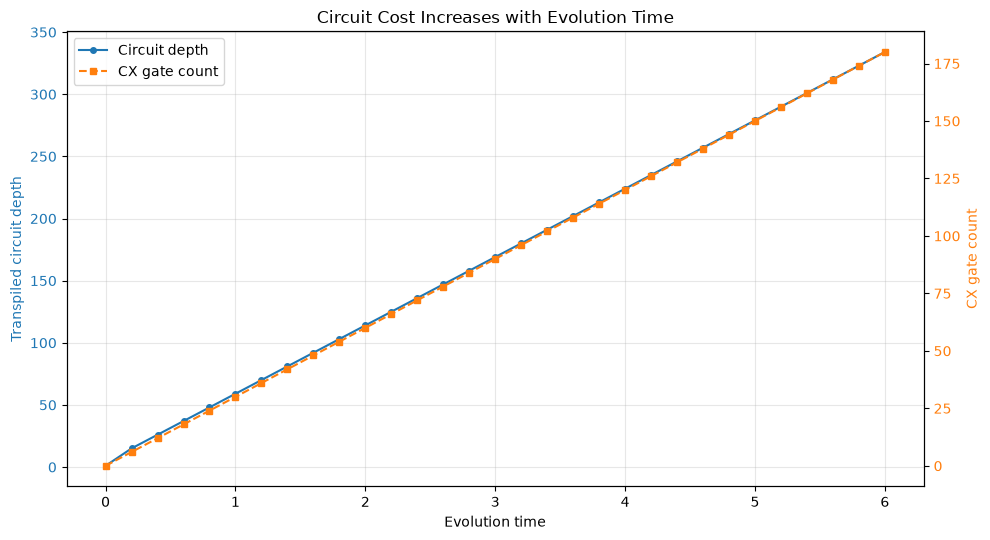

Saved: /Users/austinhandongyangicloud.com/Documents/Codex/2026-10-14/ba-s/outputs/figures/circuit_cost.png


In [14]:
fig, ax1 = plt.subplots(figsize=(10, 5.5))
depth_line = ax1.plot(
    times, compiled_depths, "o-", color="#1f77b4", markersize=4,
    label="Circuit depth"
)
ax1.set_xlabel("Evolution time")
ax1.set_ylabel("Transpiled circuit depth", color="#1f77b4")
ax1.tick_params(axis="y", labelcolor="#1f77b4")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
cx_line = ax2.plot(
    times, compiled_cx_counts, "s--", color="#ff7f0e", markersize=4,
    label="CX gate count"
)
ax2.set_ylabel("CX gate count", color="#ff7f0e")
ax2.tick_params(axis="y", labelcolor="#ff7f0e")

lines = depth_line + cx_line
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")
plt.title("Circuit Cost Increases with Evolution Time")
plt.tight_layout()

cost_figure_path = figures_dir / "circuit_cost.png"
plt.savefig(cost_figure_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", cost_figure_path)


In [15]:
required_figures = [
    figures_dir / "ideal_vs_exact.png",
    figures_dir / "noisy_vs_mitigated.png",
    figures_dir / "circuit_cost.png",
]

for path in required_figures:
    print(path.name, "| exists:", path.exists(), "| bytes:", path.stat().st_size)

assert all(path.exists() and path.stat().st_size > 0 for path in required_figures)


ideal_vs_exact.png | exists: True | bytes: 240970
noisy_vs_mitigated.png | exists: True | bytes: 348503
circuit_cost.png | exists: True | bytes: 161004


## 10. Results interpretation

The ideal first-order Trotter simulation had an RMSE of **0.031859** relative to exact classical evolution, isolating the modest algorithmic error caused by finite-step Trotterization. Adding baseline depolarizing noise increased RMSE to **0.237196** relative to ideal Trotter evolution and **0.239799** relative to exact evolution.

Zero-noise extrapolation reduced RMSE relative to the ideal Trotter result to **0.204861**, a **13.63% improvement** over the noisy baseline. End-to-end RMSE relative to exact evolution also decreased from **0.239799** to **0.206939**. The mitigation therefore recovered part of the signal but did not restore ideal dynamics. Remaining disagreement reflects residual noise, finite-shot variation, limitations of linear extrapolation, and Trotter error.

Error is small early in the trajectory but grows substantially in the later, deeper portion. The final transpiled circuit has depth **334** and **180 CX gates**, supporting the interpretation that accumulated entangling-gate noise suppresses the magnetization signal. The improvement is not free: the baseline uses 4,096 shots per time point and 126,976 total shots, while mitigation uses 12,288 shots per point and 380,928 total shots - a **3.0x sampling overhead**.


## 11. Societal impact and responsible innovation

Trustworthy quantum simulation could eventually support research in materials, medicines, batteries, and energy technologies. This experiment nevertheless shows that a plausible-looking trajectory can differ substantially from both ideal quantum evolution and an exact reference. In medicine, finance, security, or infrastructure planning, using an unverified result could allow apparent technical sophistication to hide substantial uncertainty. Error mitigation should be reported as an inference procedure, not as proof that a result is correct.

The experiment also reveals an access tradeoff. Achieving a 13.63% reduction in RMSE requires three times as many shots. On cloud hardware, those executions translate into queue time, usage allocation, and potentially financial cost. Better-resourced institutions may therefore be able to conduct more verification and obtain more reliable conclusions. Responsible use requires transparent benchmarks, uncertainty reporting, disclosure of unsuccessful mitigation, and access policies that let users verify high-stakes results rather than merely run them once.


## 12. Limitations

- The experiment uses simulated depolarizing noise rather than a physical IBM Quantum processor.
- Real hardware has qubit-specific errors, coherent errors, crosstalk, connectivity constraints, and calibration drift that are not represented here.
- Noise is amplified by changing simulator error probabilities. A hardware experiment would require a realizable method such as gate folding.
- Linear extrapolation may fail when an observable depends nonlinearly on noise strength.
- Finite-shot sampling introduces statistical variation; confidence intervals are not estimated here.
- Zero-noise extrapolation targets hardware noise but does not remove first-order Trotter error.
- The four-qubit problem is classically tractable and does not demonstrate quantum advantage.
- A 13.63% average RMSE improvement does not guarantee improvement at every time point or under a different noise model.


## 13. Conclusion

This project used Qiskit to compare exact classical TFIM dynamics, ideal first-order Trotter evolution, noisy shot-based simulation, and zero-noise extrapolation. Simulated gate noise increased RMSE relative to the ideal circuit to **0.237196**. Zero-noise extrapolation reduced it to **0.204861**, a **13.63% improvement**, while total error relative to exact evolution fell from **0.239799** to **0.206939**.

This partial recovery required **380,928 shots**, three times the sampling cost of the noisy baseline. The experiment shows that mitigation can make a noisy simulation more reliable under a controlled model, but it neither removes all error nor guarantees trustworthiness by itself. Credible quantum results require reference checks, resource and uncertainty reporting, and explicit limitations.


## Attribution and references

This project extends:

> B. Tirado, *Simulating Quantum Dynamics: The Transverse-Field Ising Model*, BasQ Qiskit Fall Fest 2026 tutorial. Tutorial text and figures: CC BY 4.0; code: Apache License 2.0.

Additional references:

1. Qiskit documentation: `PauliEvolutionGate`, `LieTrotter`, `StatevectorEstimator`, transpilation, and Aer noise models.
2. Smith, Kim, Pollmann, and Knolle, “Simulating quantum many-body dynamics on a current digital quantum computer,” *npj Quantum Information* 5, 106 (2019).
3. Kim et al., “Evidence for the utility of quantum computing before fault tolerance,” *Nature* 618, 500-505 (2023).

All quantum circuits, synthesis, transpilation, and noise simulations in this notebook use Qiskit.
